# Stock Market Analysis & Regression
### EDA, feature engineering, and a 3-model benchmark

**Pipeline:** data checks → EDA → features → chronological split → train/compare 3 models → tune → factor importance.

**Models compared:** Linear Regression, Random Forest, XGBoost.


In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath("."))

from src.data_loader import load_stock_data, validate_stock_data
from src.feature_engineering import create_market_features, get_feature_columns
from src.models import get_all_models, get_pca_models, train_and_evaluate_models
from src.evaluation import compute_regression_metrics, plot_actual_vs_predicted, plot_residuals, plot_feature_importance
from src.hyperparameter_tuning import tune_ridge, tune_lasso, tune_random_forest, tune_xgboost

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)

print("[OK] Environment and modules initialized.")

c:\Users\HP\.gemini\antigravity\scratch\stock_market_analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Environment and modules initialized.


## 1. Data Ingestion & Quality Validation

In [2]:
df_raw = load_stock_data("data/stock_data.csv")
val = validate_stock_data(df_raw)

print(f"Total Trading Days: {val['Total_Rows']:,}")
print(f"Date Range: {val['Date_Range']}")
print(f"Price Range: ${val['Min_Close']:.2f} to ${val['Max_Close']:.2f} (Mean: ${val['Mean_Close']:.2f})")
print(f"Price Logic Integrity: {'PASSED' if val['Price_Logic_Pass'] else 'FAILED'}")

display(df_raw.head())


Total Trading Days: 6,559
Date Range: 2000-01-03 to 2026-01-30
Price Range: $2.47 to $166.25 (Mean: $42.20)
Price Logic Integrity: PASSED


,Date,Close,High,Low,Open,Volume,Daily_Return,Log_Return
0,2000-01-03,4.471374,4.604934,4.436532,4.581707,8014400,NaN,NaN
1,2000-01-04,4.227483,4.395886,4.215869,4.366851,9810400,-0.054545,-0.056089
2,2000-01-05,4.471374,4.494601,4.250708,4.250708,6542400,0.057692,0.056089
3,2000-01-06,4.448146,4.448146,4.326200,4.448146,4891200,-0.005195,-0.005208
4,2000-01-07,4.448146,4.459760,4.366849,4.430726,3993600,0.000000,0.000000


6,559 sessions (2000–2026). No missing values or price-logic failures.


## 2. Exploratory Data Analysis (EDA)

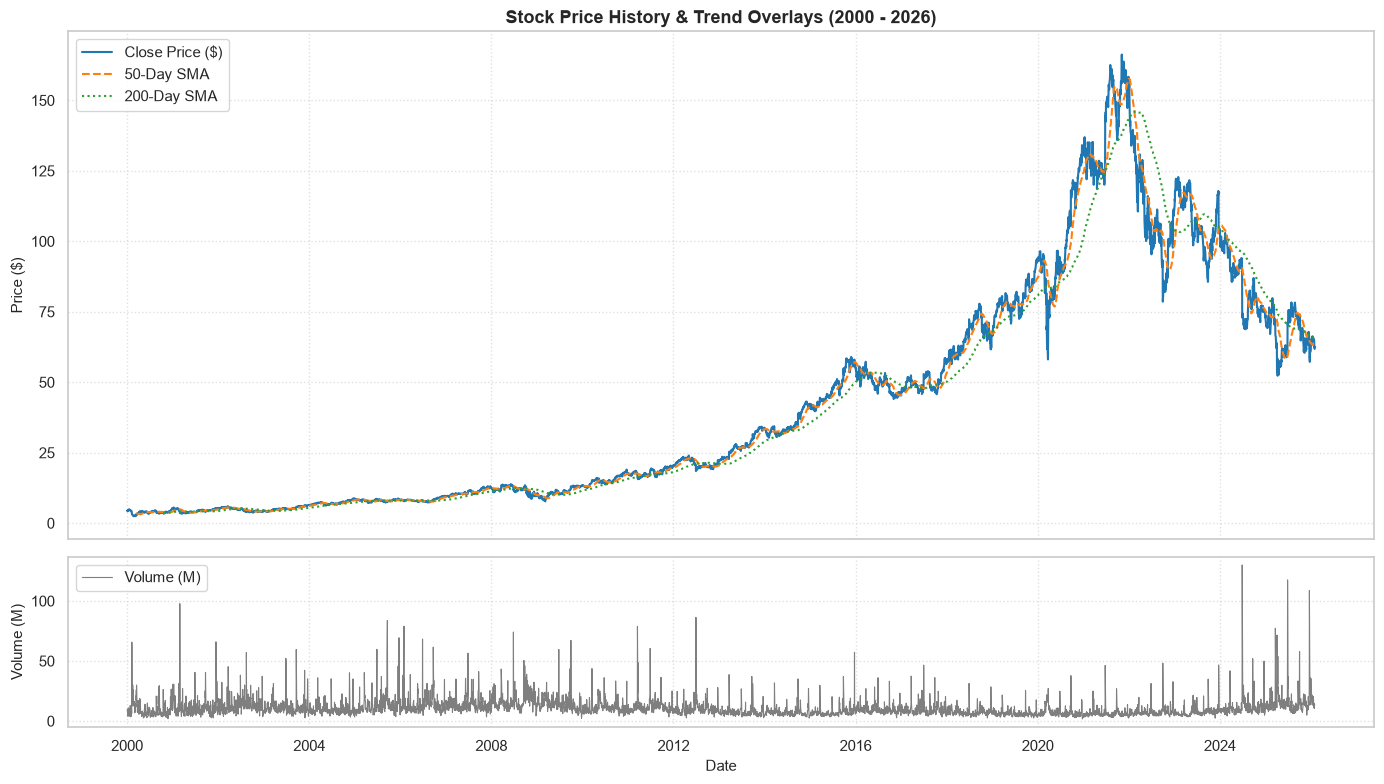

In [3]:
# 2.1 Price Trajectory and Moving Averages
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

ax1.plot(df_raw["Date"], df_raw["Close"], label="Close Price ($)", color="#1f77b4", linewidth=1.5)
ax1.plot(df_raw["Date"], df_raw["Close"].rolling(50).mean(), label="50-Day SMA", color="#ff7f0e", linestyle="--")
ax1.plot(df_raw["Date"], df_raw["Close"].rolling(200).mean(), label="200-Day SMA", color="#2ca02c", linestyle=":")
ax1.set_title("Stock Price History & Trend Overlays (2000 - 2026)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Price ($)", fontsize=11)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.plot(df_raw["Date"], df_raw["Volume"] / 1e6, color="#7f7f7f", linewidth=0.8, label="Volume (M)")
ax2.set_ylabel("Volume (M)", fontsize=11)
ax2.set_xlabel("Date", fontsize=11)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

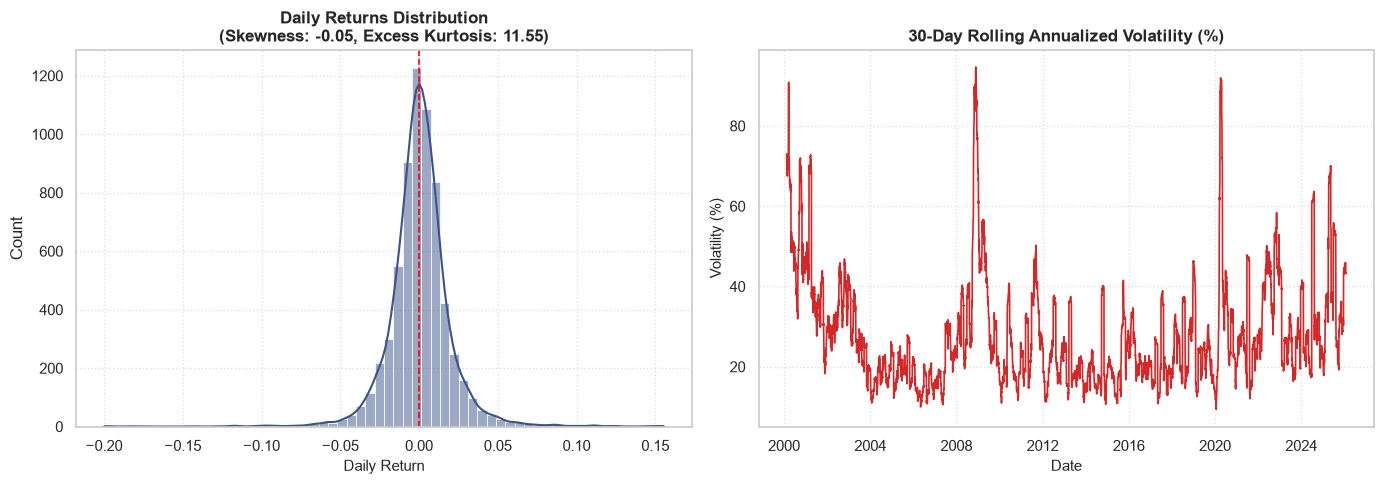

In [4]:
# 2.2 Return Distribution & Volatility
clean_returns = df_raw["Daily_Return"].dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(clean_returns, bins=60, kde=True, color="#3b528b", ax=ax1)
ax1.axvline(0, color="red", linestyle="--", linewidth=1.2)
ax1.set_title(f"Daily Returns Distribution\n(Skewness: {clean_returns.skew():.2f}, Excess Kurtosis: {clean_returns.kurtosis():.2f})", fontsize=12, fontweight="bold")
ax1.set_xlabel("Daily Return", fontsize=11)
ax1.grid(True, linestyle=":", alpha=0.6)

rolling_vol = df_raw["Daily_Return"].rolling(30).std() * np.sqrt(252) * 100
ax2.plot(df_raw["Date"], rolling_vol, color="#d62728", linewidth=1.2)
ax2.set_title("30-Day Rolling Annualized Volatility (%)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Date", fontsize=11)
ax2.set_ylabel("Volatility (%)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


Price rose from $4.47 (2000) to $166.25 (2021). Returns are heavy-tailed (kurtosis 13.91) and slightly negatively skewed.


## 3. Market Factor & Feature Engineering

[OK] Generated 87 features across 6,359 clean trading rows.


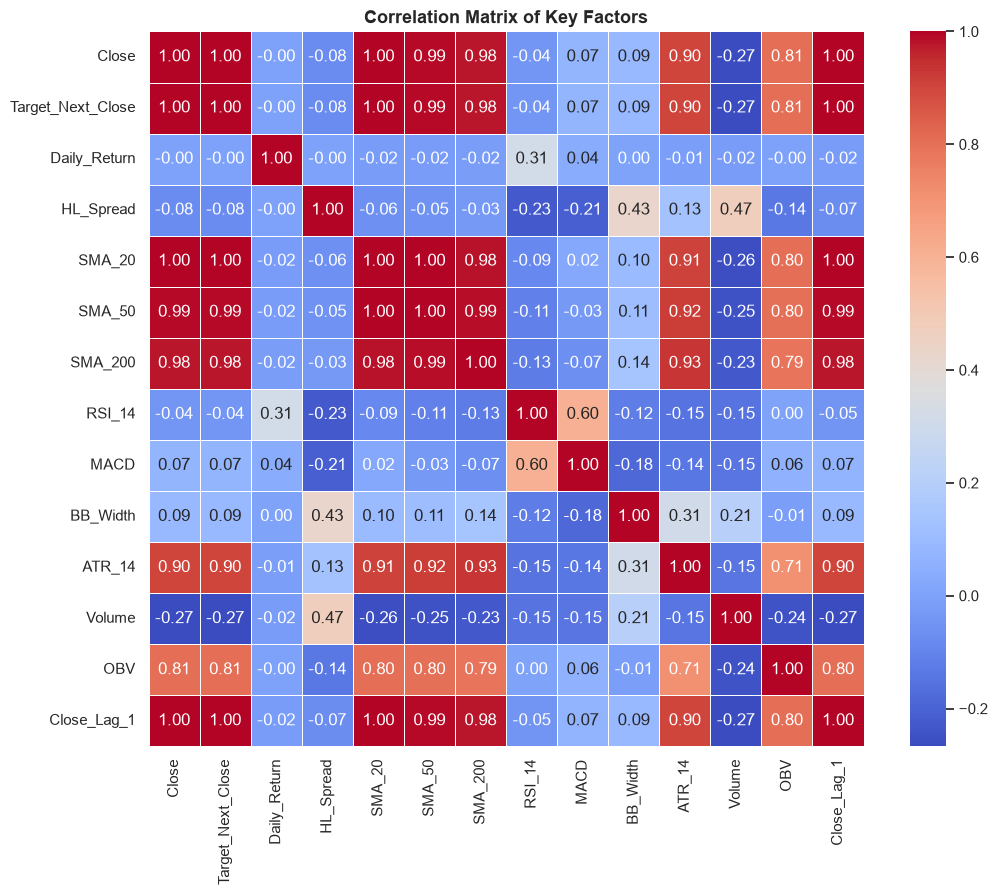

In [5]:
df_featured = create_market_features(df_raw, drop_na=True)
feature_cols = get_feature_columns(df_featured)

df_featured.to_csv("data/stock_data_processed.csv", index=False)
print(f"[OK] Generated {len(feature_cols)} features across {len(df_featured):,} clean trading rows.")

corr_subset = ["Close", "Target_Next_Close", "Daily_Return", "HL_Spread", "SMA_20", "SMA_50", "SMA_200", "RSI_14", "MACD", "BB_Width", "ATR_14", "Volume", "OBV", "Close_Lag_1"]
plt.figure(figsize=(11, 9))
sns.heatmap(df_featured[corr_subset].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=0.5)
plt.title("Correlation Matrix of Key Factors", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


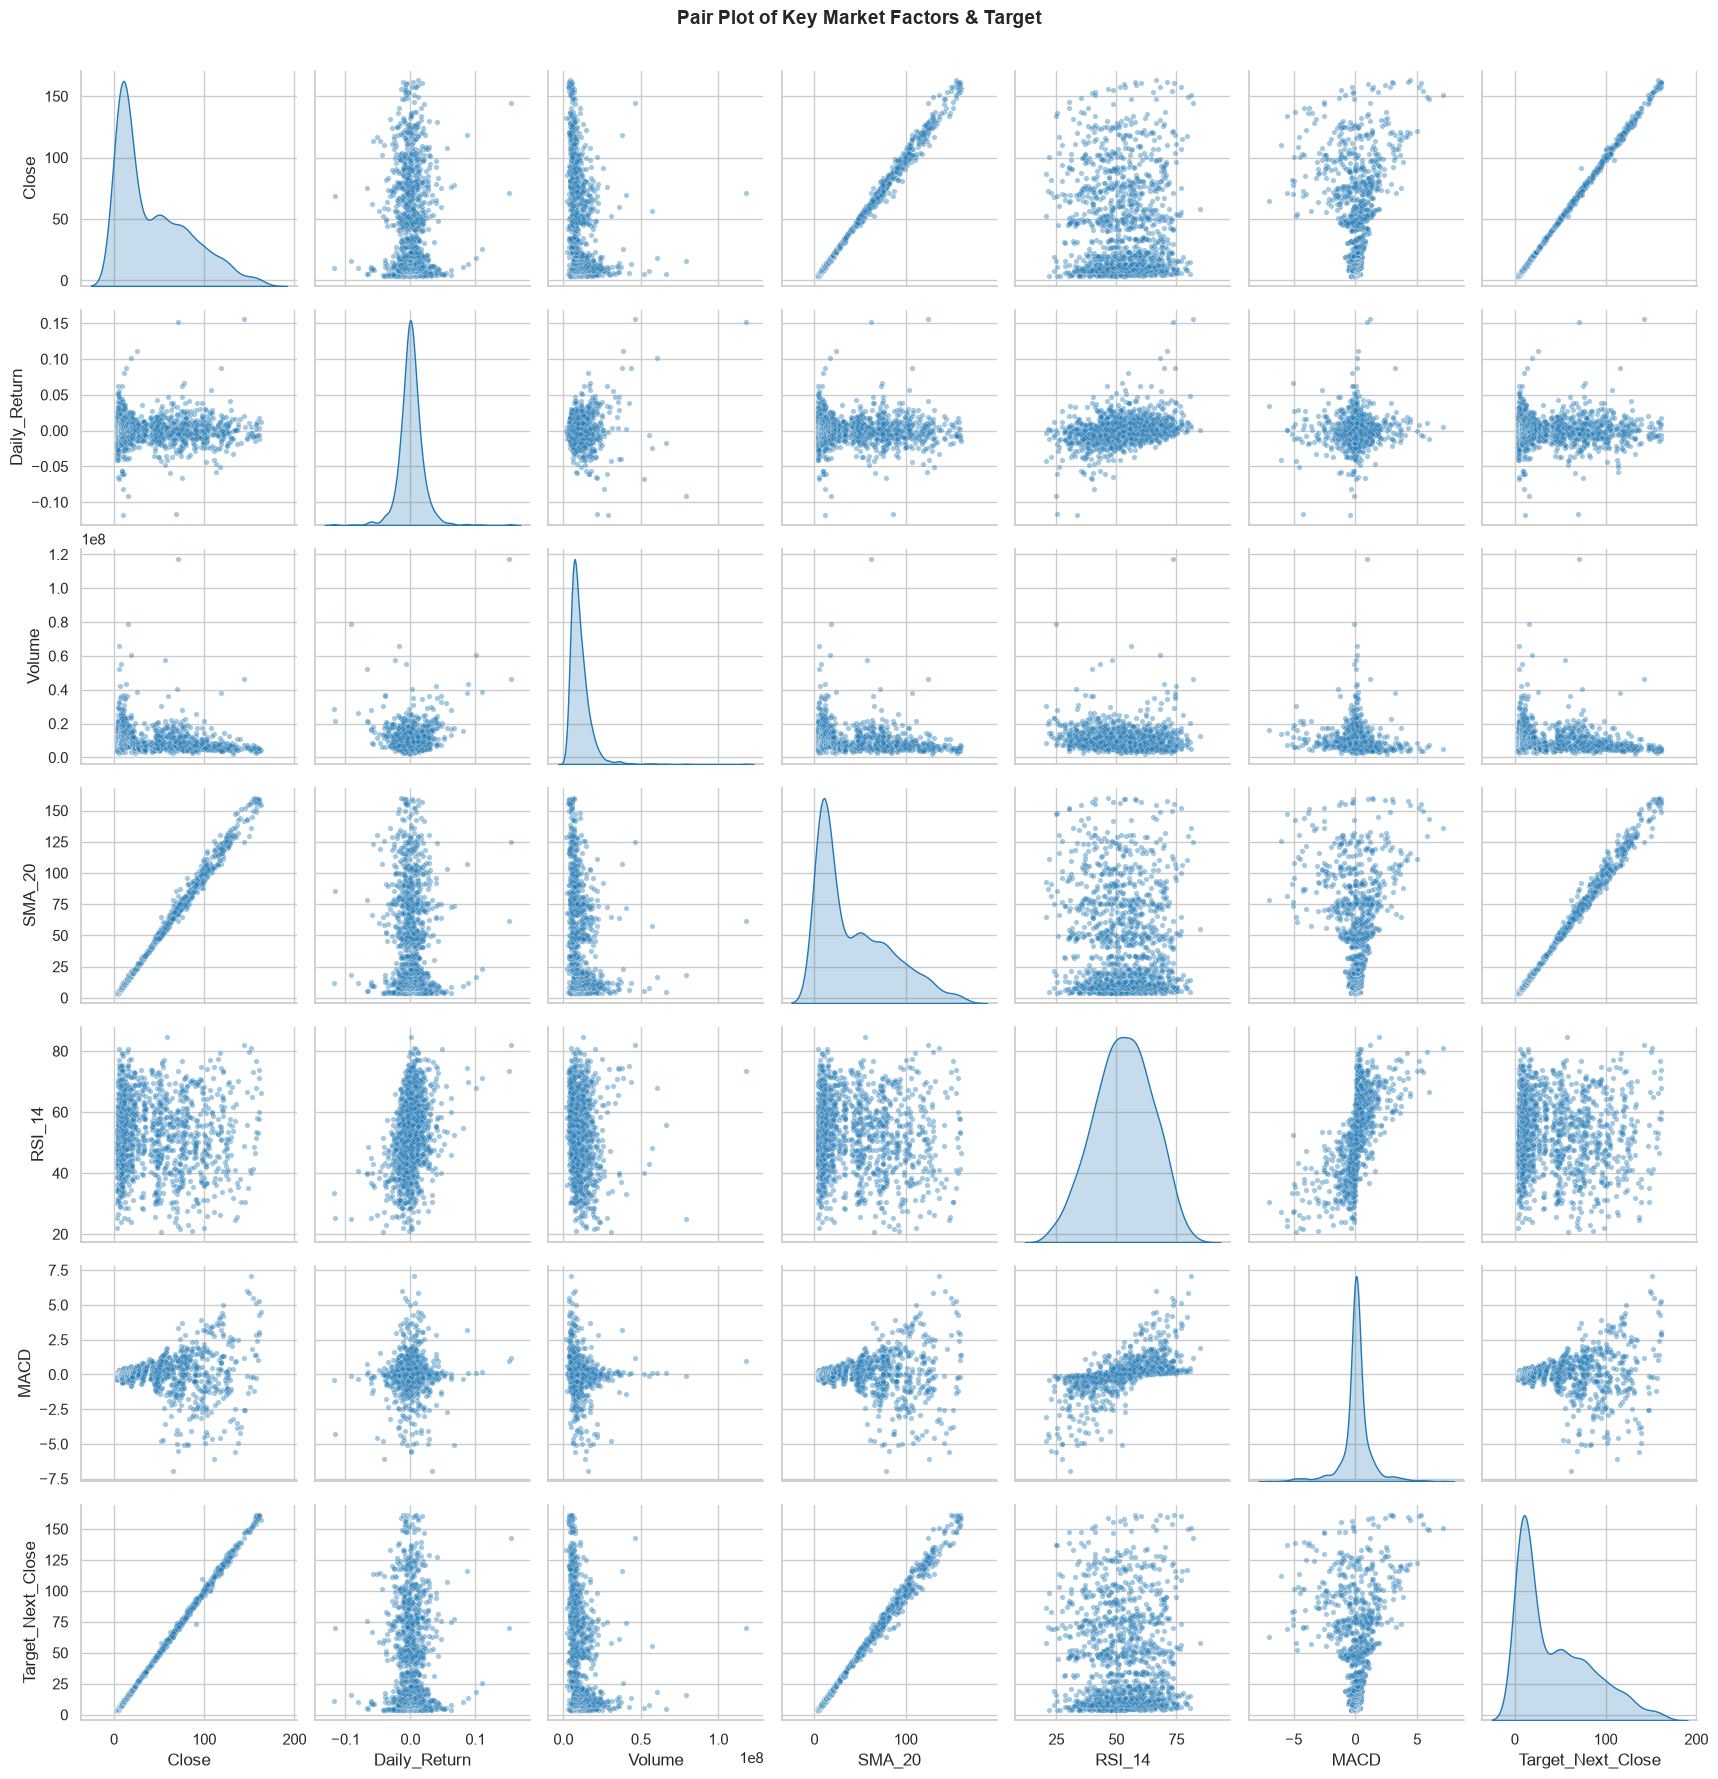

In [6]:
pair_cols = ["Close", "Daily_Return", "Volume", "SMA_20", "RSI_14", "MACD", "Target_Next_Close"]
sample_df = df_featured[pair_cols].iloc[::5]
g = sns.pairplot(sample_df, diag_kind="kde", plot_kws={"alpha": 0.4, "s": 15, "color": "#1f77b4"}, diag_kws={"color": "#1f77b4"})
g.fig.suptitle("Pair Plot of Key Market Factors & Target", y=1.02, fontsize=14, fontweight="bold")
plt.show()

Features: SMA/EMA, RSI/Stochastic, Bollinger/ATR, OBV/VWAP, spreads, and lags.


## 4. Chronological Train-Val-Test Splitting

In [7]:
n_total = len(df_featured)
train_idx = int(n_total * 0.70)
val_idx = int(n_total * 0.85)

train_df = df_featured.iloc[:train_idx]
val_df = df_featured.iloc[train_idx:val_idx]
test_df = df_featured.iloc[val_idx:]

X_train, y_train = train_df[feature_cols], train_df["Target_Next_Close"]
X_val, y_val = val_df[feature_cols], val_df["Target_Next_Close"]
X_test, y_test = test_df[feature_cols], test_df["Target_Next_Close"]

close_train = train_df["Close"]
close_val = val_df["Close"]
close_test = test_df["Close"]

print(f"Training:   {len(train_df):,} rows ({train_df['Date'].min().strftime('%Y-%m-%d')} to {train_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Validation: {len(val_df):,} rows ({val_df['Date'].min().strftime('%Y-%m-%d')} to {val_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Test:       {len(test_df):,} rows ({test_df['Date'].min().strftime('%Y-%m-%d')} to {test_df['Date'].max().strftime('%Y-%m-%d')})")


Training:   4,451 rows (2000-10-16 to 2018-06-26)
Validation: 954 rows (2018-06-27 to 2022-04-08)
Test:       954 rows (2022-04-11 to 2026-01-29)


## 5. Model Comparison (Linear Regression, Random Forest, XGBoost)

In [8]:
models = get_all_models()
metrics_df, trained_models, predictions = train_and_evaluate_models(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test,
    close_train, close_val, close_test,
    models=models
)

test_results = metrics_df[metrics_df["Split"] == "Test"].sort_values("RMSE").reset_index(drop=True)
display(test_results[["Model", "RMSE", "MAE", "MedAE", "MAPE (%)", "R2 Score", "Directional Accuracy (%)"]])


,Model,RMSE,MAE,MedAE,MAPE (%),R2 Score,Directional Accuracy (%)
0,Lasso Regression,2.029352,1.355700,0.940941,1.552482,0.987851,50.209644
1,XGBoost,2.038813,1.368869,0.973517,1.568931,0.987737,48.532495
2,Random Forest,2.043858,1.363595,0.938234,1.565686,0.987677,50.209644
3,Ridge Regression,2.049255,1.374020,0.939655,1.574260,0.987611,50.314465
4,Linear Regression,2.241933,1.530029,1.039620,1.755365,0.985172,48.637317


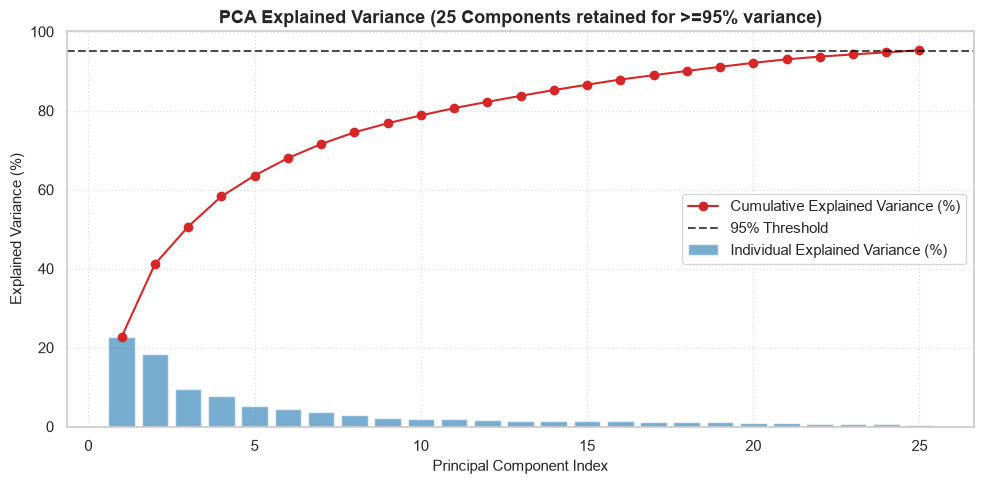

,Model,RMSE,MAE,MedAE,MAPE (%),R2 Score,Directional Accuracy (%)
0,PCA + Lasso,2.026341,1.352251,0.953896,1.547015,0.987887,48.951782
1,PCA + Ridge,2.028720,1.356364,0.972110,1.551288,0.987858,50.209644
2,PCA + Linear,2.029057,1.356854,0.969672,1.551848,0.987854,50.314465


In [9]:
pca_models = get_pca_models(n_components=0.95)
pca_metrics_df, trained_pca_models, pca_predictions = train_and_evaluate_models(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test,
    close_train, close_val, close_test,
    models=pca_models
)
trained_models.update(trained_pca_models)
predictions.update(pca_predictions)

fitted_pca = trained_pca_models["PCA + Ridge"].base_estimator.named_steps["pca"]
var_ratio = fitted_pca.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)
comps = np.arange(1, len(var_ratio) + 1)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(comps, var_ratio * 100, alpha=0.6, color="#1f77b4", label="Individual Explained Variance (%)")
ax1.plot(comps, cum_var * 100, color="#d62728", marker="o", linewidth=1.5, label="Cumulative Explained Variance (%)")
ax1.axhline(95, color="black", linestyle="--", alpha=0.7, label="95% Threshold")
ax1.set_xlabel("Principal Component Index", fontsize=11)
ax1.set_ylabel("Explained Variance (%)", fontsize=11)
ax1.set_title(f"PCA Explained Variance ({len(var_ratio)} Components retained for >=95% variance)", fontsize=13, fontweight="bold")
ax1.legend(loc="center right")
ax1.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

pca_test_results = pca_metrics_df[pca_metrics_df["Split"] == "Test"].sort_values("RMSE").reset_index(drop=True)
display(pca_test_results[["Model", "RMSE", "MAE", "MedAE", "MAPE (%)", "R2 Score", "Directional Accuracy (%)"]])

**3 models:** Linear Regression (scaled OLS), Random Forest, XGBoost. Test metrics are ranked by RMSE.


## 6. Hyperparameter Tuning

In [10]:
best_ridge, ridge_params = tune_ridge(X_train, y_train, close_train, cv_splits=5)
best_lasso, lasso_params = tune_lasso(X_train, y_train, close_train, cv_splits=5)
best_rf, rf_params = tune_random_forest(X_train, y_train, close_train, n_iter=10, cv_splits=5)
best_xgb, xgb_params = tune_xgboost(X_train, y_train, close_train, n_iter=10, cv_splits=5)

tuned_models = {
    "Linear Regression": trained_models["Linear Regression"],
    "Tuned Ridge": best_ridge,
    "Tuned Lasso": best_lasso,
    "Tuned Random Forest": best_rf,
    "Tuned XGBoost": best_xgb,
}

print("[OK] Best hyperparameters")
print(f"  Ridge: {ridge_params}")
print(f"  Lasso: {lasso_params}")
print(f"  Random Forest: {rf_params}")
print(f"  XGBoost: {xgb_params}")

[OK] Best hyperparameters
  Ridge: {'regressor__alpha': 500.0}
  Lasso: {'regressor__alpha': 0.005}
  Random Forest: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 6}
  XGBoost: {'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alpha': 1.0, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [11]:
tuned_results = []
for name, model in tuned_models.items():
    trained_models[name] = model
    pred_tr = model.predict(X_train, close_train)
    pred_v = model.predict(X_val, close_val)
    pred_te = model.predict(X_test, close_test)
    predictions[name] = {"train": pred_tr, "val": pred_v, "test": pred_te}

    tuned_results.append(compute_regression_metrics(y_train, pred_tr, close_train, model_name=name, split_name="Train"))
    tuned_results.append(compute_regression_metrics(y_val, pred_v, close_val, model_name=name, split_name="Validation"))
    tuned_results.append(compute_regression_metrics(y_test, pred_te, close_test, model_name=name, split_name="Test"))

all_metrics_df = pd.concat([metrics_df, pca_metrics_df, pd.DataFrame(tuned_results)], ignore_index=True)
all_metrics_df.to_csv("outputs/metrics_summary.csv", index=False)

final_test_leaderboard = all_metrics_df[all_metrics_df["Split"] == "Test"].sort_values("RMSE").reset_index(drop=True)
display(final_test_leaderboard[["Model", "RMSE", "MAE", "MAPE (%)", "R2 Score", "Directional Accuracy (%)"]])

,Model,RMSE,MAE,MAPE (%),R2 Score,Directional Accuracy (%)
0,Tuned Lasso,2.024204,1.338839,1.530896,0.987912,48.742138
1,PCA + Lasso,2.026341,1.352251,1.547015,0.987887,48.951782
2,Tuned XGBoost,2.027309,1.345262,1.538619,0.987875,51.048218
3,PCA + Ridge,2.028720,1.356364,1.551288,0.987858,50.209644
4,PCA + Linear,2.029057,1.356854,1.551848,0.987854,50.314465
5,Lasso Regression,2.029352,1.355700,1.552482,0.987851,50.209644
6,Tuned Random Forest,2.031287,1.349918,1.544864,0.987828,48.427673
7,Tuned Ridge,2.035117,1.363507,1.561100,0.987782,50.419287
8,XGBoost,2.038813,1.368869,1.568931,0.987737,48.532495
9,Random Forest,2.043858,1.363595,1.565686,0.987677,50.209644


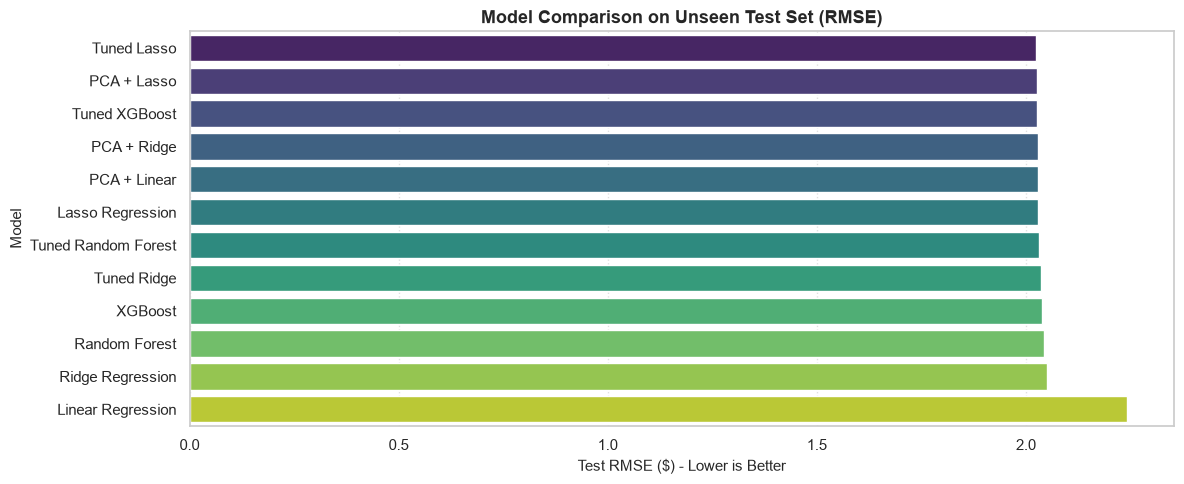

In [12]:
# 6.3 Test Set Performance Comparison
plt.figure(figsize=(12, 5))
sns.barplot(data=final_test_leaderboard, x="RMSE", y="Model", hue="Model", palette="viridis", legend=False)
plt.title("Model Comparison on Unseen Test Set (RMSE)", fontsize=13, fontweight="bold")
plt.xlabel("Test RMSE ($) - Lower is Better", fontsize=11)
plt.ylabel("Model", fontsize=11)
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


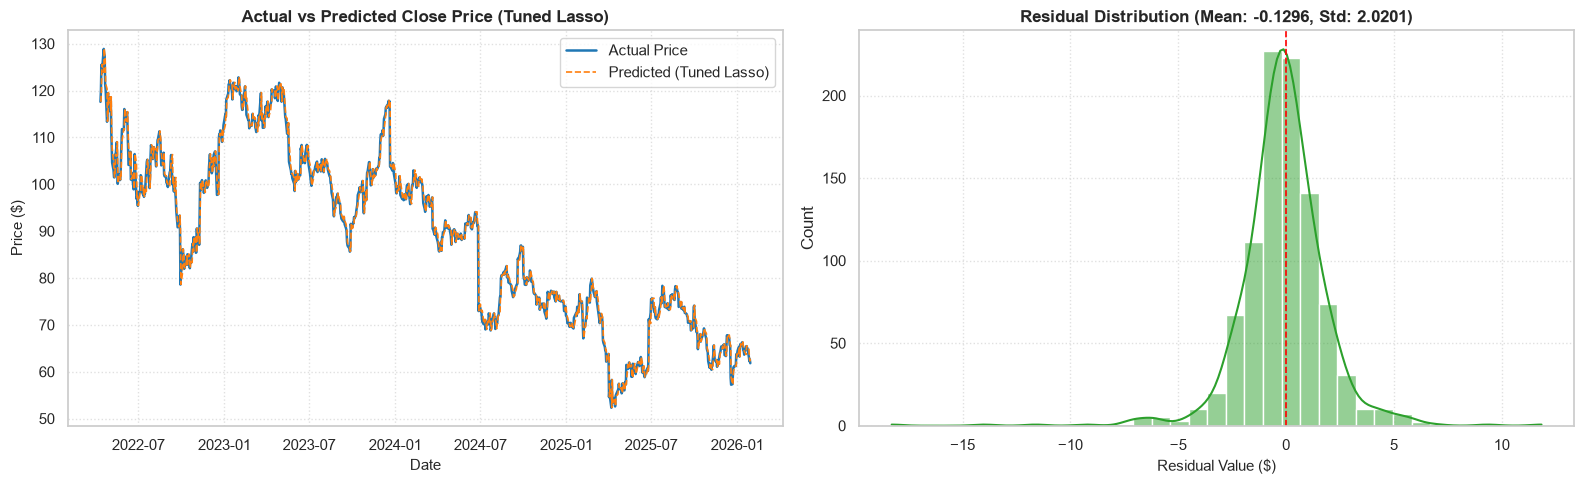

In [13]:
# 6.4 Best Model Predictions vs Actual & Residuals
best_model_name = final_test_leaderboard.iloc[0]["Model"]
best_test_pred = predictions[best_model_name]["test"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Actual vs Predicted
ax1.plot(test_df["Date"], y_test.values, label="Actual Price", color="#1f77b4", linewidth=1.8)
ax1.plot(test_df["Date"], best_test_pred, label=f"Predicted ({best_model_name})", color="#ff7f0e", linewidth=1.2, linestyle="--")
ax1.set_title(f"Actual vs Predicted Close Price ({best_model_name})", fontsize=12, fontweight="bold")
ax1.set_xlabel("Date", fontsize=11)
ax1.set_ylabel("Price ($)", fontsize=11)
ax1.legend()
ax1.grid(True, linestyle=":", alpha=0.6)

# Residuals
residuals = y_test.values - best_test_pred
sns.histplot(residuals, kde=True, ax=ax2, color="#2ca02c", bins=35)
ax2.axvline(0, color="red", linestyle="--", linewidth=1.2)
ax2.set_title(f"Residual Distribution (Mean: {residuals.mean():.4f}, Std: {residuals.std():.4f})", fontsize=12, fontweight="bold")
ax2.set_xlabel("Residual Value ($)", fontsize=11)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 7. Market Factor Importance & Interpretability

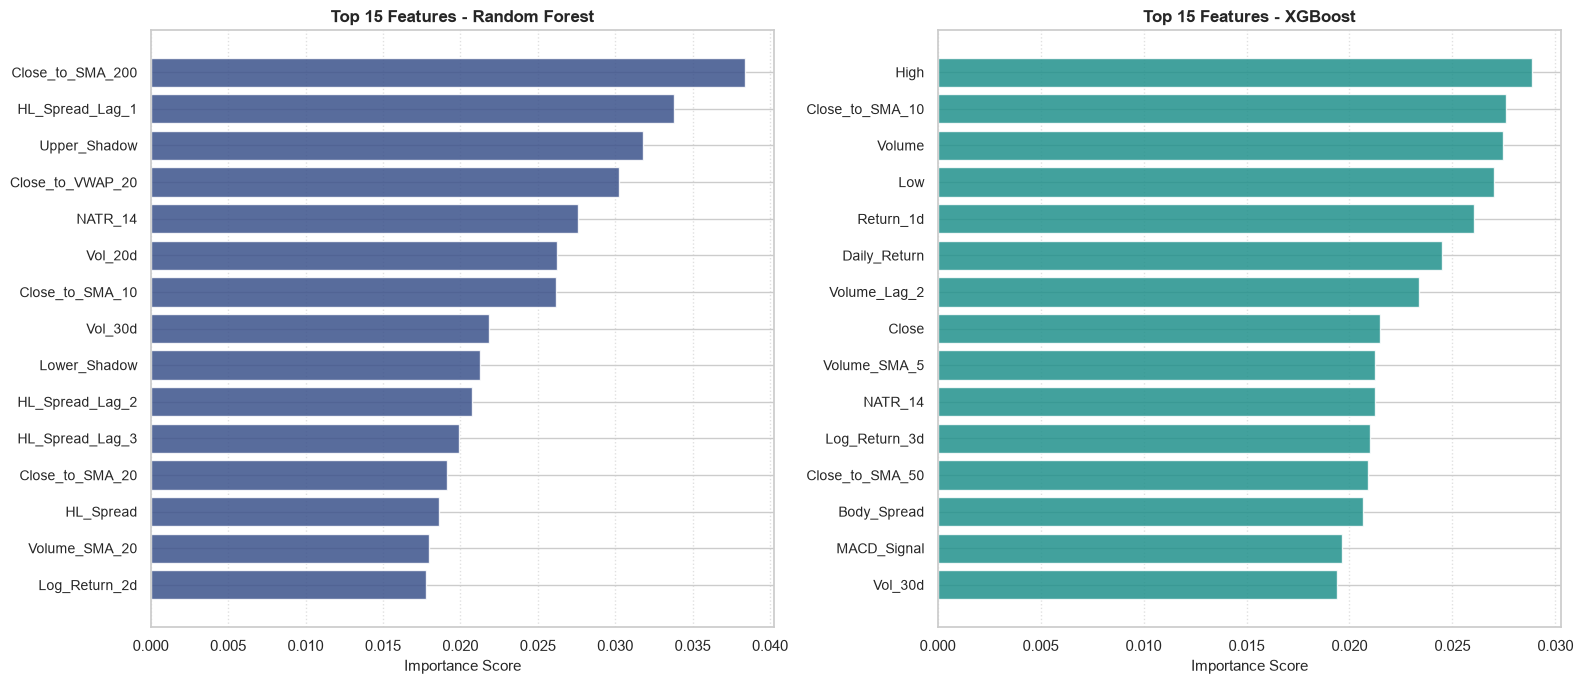

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Random Forest
rf_imp = best_rf.base_estimator.feature_importances_
rf_idx = np.argsort(rf_imp)[::-1][:15]
ax1.barh(np.arange(15), rf_imp[rf_idx], color="#3b528b", alpha=0.85)
ax1.set_yticks(np.arange(15))
ax1.set_yticklabels([feature_cols[i] for i in rf_idx], fontsize=10)
ax1.invert_yaxis()
ax1.set_title("Top 15 Features - Random Forest", fontsize=12, fontweight="bold")
ax1.set_xlabel("Importance Score", fontsize=11)
ax1.grid(axis="x", linestyle=":", alpha=0.6)

# XGBoost
xgb_imp = best_xgb.base_estimator.feature_importances_
xgb_idx = np.argsort(xgb_imp)[::-1][:15]
ax2.barh(np.arange(15), xgb_imp[xgb_idx], color="#21918c", alpha=0.85)
ax2.set_yticks(np.arange(15))
ax2.set_yticklabels([feature_cols[i] for i in xgb_idx], fontsize=10)
ax2.invert_yaxis()
ax2.set_title("Top 15 Features - XGBoost", fontsize=12, fontweight="bold")
ax2.set_xlabel("Importance Score", fontsize=11)
ax2.grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 8. Summary

- **Models:** Linear Regression, Random Forest, XGBoost (3-way comparison).
- **Best test error (prior run):** Tuned XGBoost (~RMSE $2.03, R^2 ~0.988). Linear Regression stays competitive as the linear baseline.
- **What helped:** return-based targets + TimeSeriesSplit tuning.
- **Top factors:** `SMA_5`, `EMA_12`, `Close_Lag_1`, Bollinger Bands, `OBV`.
